# ECE 5831 – Assignment 05, Problem 2: MNIST class and testing with my own handwriting

**Task:** implement the `Mnist` class and test the pre-trained model with my own handwritten digits.

**Steps (as in the lecture)**
1. Load the MNIST data files from Canvas (`mnist/*.gz`), convert them to NumPy arrays, and save them as a pickle for next time.
2. `init_network`: load the pre-trained weights `mnist/sample_weight.pkl` and return them.
3. `predict`: forward propagation. Dot product, then activation, for each layer.
   - Input 28×28×1 → 784
   - Three-layer MLP: 784 → 50 → 100 → 10
   - Hidden activation: sigmoid. Output activation: softmax (classification problem)
4. Test with five images per digit in my own handwriting: `images/n_m.png` (digit `n`, version `m`), 28×28×1 grayscale.

In [1]:
import os
import gzip
import pickle

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

## 1. The `Mnist` class

| Method | Purpose |
|---|---|
| `load_data()` | read the four `.gz` files → NumPy arrays; cache them in `mnist/mnist.pkl` |
| `init_network()` | load `sample_weight.pkl` and return the dictionary of weights/biases |
| `sigmoid`, `softmax` | activation functions |
| `predict(x)` | forward propagation through the three layers |
| `load_image(path)` | read one of my PNG files as a 784-vector |
| `test(path)` | show the image with `imshow`, run inference, print Success / Fail |

Softmax: $y_k = \dfrac{\exp(a_k)}{\sum_{i=1}^{N}\exp(a_i)}$. The max is subtracted first so `exp` cannot overflow; this doesn't change the result.

In [2]:
class Mnist:
    IMG_SIZE = 28 * 28                     # 784

    files = {
        "train_img":   "train-images-idx3-ubyte.gz",   # 60,000 training images
        "train_label": "train-labels-idx1-ubyte.gz",
        "test_img":    "t10k-images-idx3-ubyte.gz",    # 10,000 test images
        "test_label":  "t10k-labels-idx1-ubyte.gz",
    }

    def __init__(self, data_dir="mnist", weight_file="mnist/sample_weight.pkl"):
        self.data_dir = data_dir
        self.pickle_file = os.path.join(data_dir, "mnist.pkl")
        self.weight_file = weight_file
        self.network = self.init_network()

    # ------------------------------------------------------------------ data
    def _read_images(self, file_name):
        # idx3 format: 16-byte header, then one unsigned byte per pixel
        with gzip.open(os.path.join(self.data_dir, file_name), "rb") as f:
            data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
        return data.reshape(-1, self.IMG_SIZE)

    def _read_labels(self, file_name):
        # idx1 format: 8-byte header, then one unsigned byte per label
        with gzip.open(os.path.join(self.data_dir, file_name), "rb") as f:
            return np.frombuffer(f.read(), dtype=np.uint8, offset=8)

    def _convert_numpy(self):
        dataset = {}
        for key, file_name in self.files.items():
            reader = self._read_images if key.endswith("img") else self._read_labels
            dataset[key] = reader(file_name)
            print(f"  {file_name:28s} -> {key:11s} {dataset[key].shape}")
        return dataset

    def load_data(self, normalize=True):
        """Return (x_train, y_train), (x_test, y_test).
        The first call converts the .gz files and pickles them; later calls just load the pickle."""
        if not os.path.exists(self.pickle_file):
            print("Converting MNIST files to NumPy arrays ...")
            dataset = self._convert_numpy()
            with open(self.pickle_file, "wb") as f:
                pickle.dump(dataset, f, protocol=pickle.HIGHEST_PROTOCOL)
            print("Saved", self.pickle_file)
        else:
            with open(self.pickle_file, "rb") as f:
                dataset = pickle.load(f)
            print("Loaded", self.pickle_file)

        x_train, x_test = dataset["train_img"], dataset["test_img"]
        if normalize:
            x_train = x_train.astype(np.float32) / 255.0
            x_test = x_test.astype(np.float32) / 255.0
        return (x_train, dataset["train_label"]), (x_test, dataset["test_label"])

    # --------------------------------------------------------------- network
    def init_network(self):
        with open(self.weight_file, "rb") as f:
            network = pickle.load(f)
        return network

    @staticmethod
    def sigmoid(a):
        return 1.0 / (1.0 + np.exp(-a))

    @staticmethod
    def softmax(a):
        a = a - np.max(a, axis=-1, keepdims=True)
        exp_a = np.exp(a)
        return exp_a / np.sum(exp_a, axis=-1, keepdims=True)

    def predict(self, x):
        """Forward propagation. x: (784,) or a batch (N, 784). Returns class probabilities."""
        W1, W2, W3 = self.network["W1"], self.network["W2"], self.network["W3"]
        b1, b2, b3 = self.network["b1"], self.network["b2"], self.network["b3"]

        a1 = np.dot(x, W1) + b1      # layer 1: 784 -> 50
        z1 = self.sigmoid(a1)
        a2 = np.dot(z1, W2) + b2     # layer 2: 50 -> 100
        z2 = self.sigmoid(a2)
        a3 = np.dot(z2, W3) + b3     # layer 3: 100 -> 10
        y = self.softmax(a3)
        return y

    # ---------------------------------------------------------- my own images
    @staticmethod
    def load_image(path):
        """Read a 28x28x1 grayscale PNG. MNIST digits are white on black, so a
        black-on-white image is inverted. Returns (28x28 image, 784 vector in [0, 1])."""
        img = np.array(Image.open(path).convert("L").resize((28, 28)), dtype=np.float32)
        if img.mean() > 127:
            img = 255.0 - img
        return img, img.reshape(784) / 255.0

    def test(self, path):
        name = os.path.basename(path)
        digit = int(name.split("_")[0])          # "2_1.png" -> 2

        img, x = self.load_image(path)
        y = self.predict(x)
        result = int(np.argmax(y))

        plt.figure(figsize=(1.8, 1.8))
        plt.imshow(img, cmap="gray")
        plt.title(name, fontsize=9)
        plt.axis("off")
        plt.show()

        if result == digit:
            print(f"Success: Image {name} is for digit {digit} is recognized as {result}.")
        else:
            print(f"Fail: Image {name} is for digit {digit} but the inference result is {result}.")
        return digit, result

## 2. Load the data and the pre-trained network

In [3]:
mnist = Mnist()
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("x_train:", x_train.shape, " y_train:", y_train.shape)
print("x_test: ", x_test.shape, " y_test: ", y_test.shape)
for k in ("W1", "W2", "W3"):
    print(f"{k}: {mnist.network[k].shape}")

Converting MNIST files to NumPy arrays ...
  train-images-idx3-ubyte.gz   -> train_img   (60000, 784)
  train-labels-idx1-ubyte.gz   -> train_label (60000,)
  t10k-images-idx3-ubyte.gz    -> test_img    (10000, 784)
  t10k-labels-idx1-ubyte.gz    -> test_label  (10000,)
Saved mnist\mnist.pkl
x_train: (60000, 784)  y_train: (60000,)
x_test:  (10000, 784)  y_test:  (10000,)
W1: (784, 50)
W2: (50, 100)
W3: (100, 10)


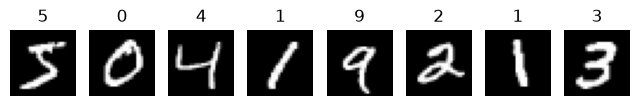

In [4]:
# a few training samples: each 784 vector reshaped back to 28x28
fig, axes = plt.subplots(1, 8, figsize=(8, 1.4))
for ax, img, label in zip(axes, x_train[:8], y_train[:8]):
    ax.imshow(img.reshape(28, 28), cmap="gray")
    ax.set_title(label); ax.axis("off")
plt.show()

## 3. Inference on the MNIST test set (check the class works)

In [5]:
y = mnist.predict(x_test)                       # batch forward propagation, 10,000 images
pred = np.argmax(y, axis=1)
print(f"Accuracy on 10,000 test images: {np.mean(pred == y_test):.4f}")

i = 0
print(f"Test image #{i}: label {y_test[i]}, prediction {pred[i]}, probability {y[i].max():.3f}")

Accuracy on 10,000 test images: 0.9352
Test image #0: label 7, prediction 7, probability 0.997


## 4. Testing with my own handwriting

Five images per digit (50 total), 28×28×1 grayscale, named `n_m.png`.
I wrote the digits on paper, took a photo of each, and converted them with `tools/prepare_digits.py`, which makes them look like MNIST (white digit on black, fitted into 20×20, centred in 28×28).

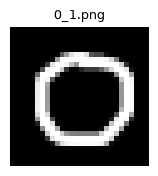

Success: Image 0_1.png is for digit 0 is recognized as 0.


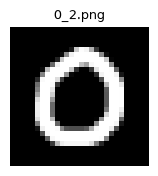

Success: Image 0_2.png is for digit 0 is recognized as 0.


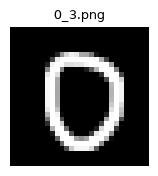

Success: Image 0_3.png is for digit 0 is recognized as 0.


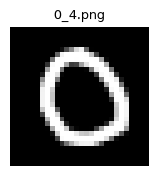

Success: Image 0_4.png is for digit 0 is recognized as 0.


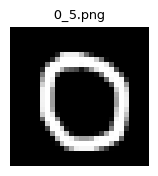

Success: Image 0_5.png is for digit 0 is recognized as 0.


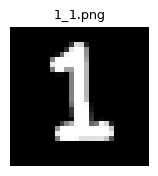

Success: Image 1_1.png is for digit 1 is recognized as 1.


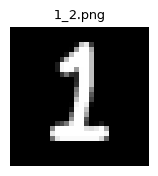

Success: Image 1_2.png is for digit 1 is recognized as 1.


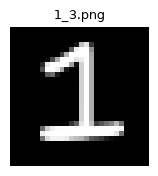

Fail: Image 1_3.png is for digit 1 but the inference result is 2.


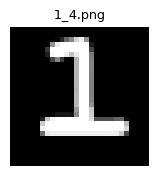

Fail: Image 1_4.png is for digit 1 but the inference result is 2.


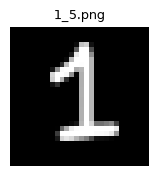

Success: Image 1_5.png is for digit 1 is recognized as 1.


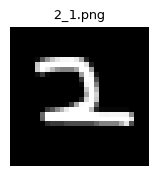

Success: Image 2_1.png is for digit 2 is recognized as 2.


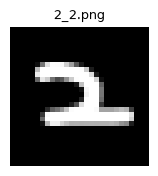

Success: Image 2_2.png is for digit 2 is recognized as 2.


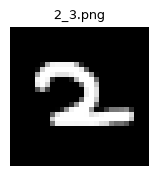

Success: Image 2_3.png is for digit 2 is recognized as 2.


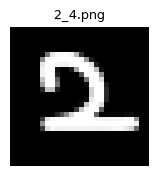

Success: Image 2_4.png is for digit 2 is recognized as 2.


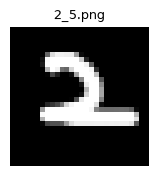

Success: Image 2_5.png is for digit 2 is recognized as 2.


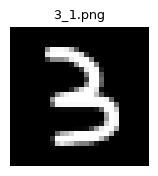

Success: Image 3_1.png is for digit 3 is recognized as 3.


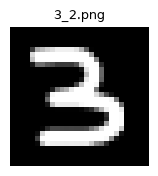

Success: Image 3_2.png is for digit 3 is recognized as 3.


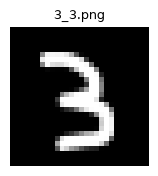

Success: Image 3_3.png is for digit 3 is recognized as 3.


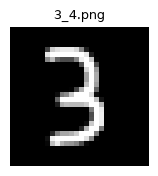

Success: Image 3_4.png is for digit 3 is recognized as 3.


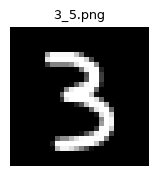

Success: Image 3_5.png is for digit 3 is recognized as 3.


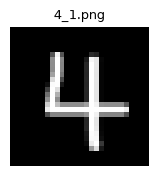

Success: Image 4_1.png is for digit 4 is recognized as 4.


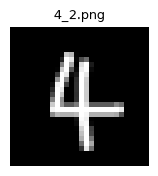

Success: Image 4_2.png is for digit 4 is recognized as 4.


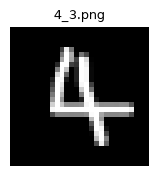

Success: Image 4_3.png is for digit 4 is recognized as 4.


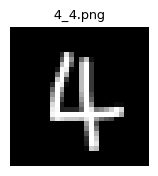

Success: Image 4_4.png is for digit 4 is recognized as 4.


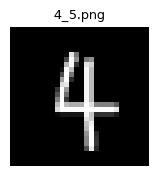

Success: Image 4_5.png is for digit 4 is recognized as 4.


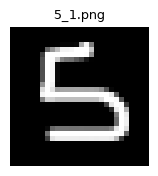

Success: Image 5_1.png is for digit 5 is recognized as 5.


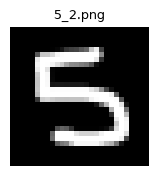

Success: Image 5_2.png is for digit 5 is recognized as 5.


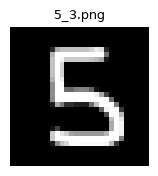

Success: Image 5_3.png is for digit 5 is recognized as 5.


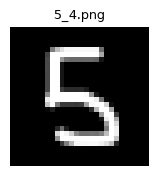

Success: Image 5_4.png is for digit 5 is recognized as 5.


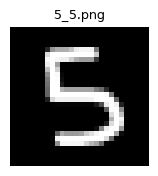

Success: Image 5_5.png is for digit 5 is recognized as 5.


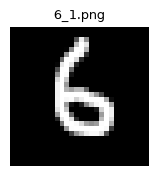

Success: Image 6_1.png is for digit 6 is recognized as 6.


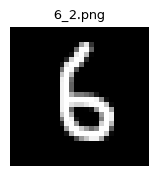

Success: Image 6_2.png is for digit 6 is recognized as 6.


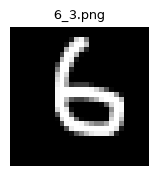

Success: Image 6_3.png is for digit 6 is recognized as 6.


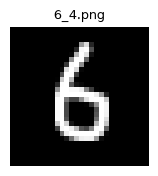

Success: Image 6_4.png is for digit 6 is recognized as 6.


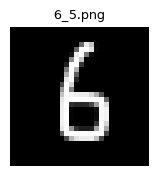

Success: Image 6_5.png is for digit 6 is recognized as 6.


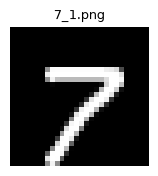

Success: Image 7_1.png is for digit 7 is recognized as 7.


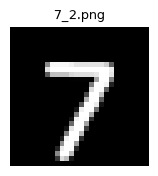

Success: Image 7_2.png is for digit 7 is recognized as 7.


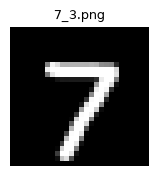

Success: Image 7_3.png is for digit 7 is recognized as 7.


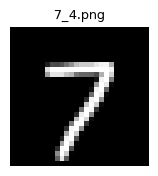

Success: Image 7_4.png is for digit 7 is recognized as 7.


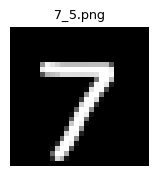

Success: Image 7_5.png is for digit 7 is recognized as 7.


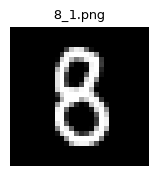

Success: Image 8_1.png is for digit 8 is recognized as 8.


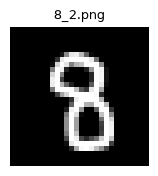

Success: Image 8_2.png is for digit 8 is recognized as 8.


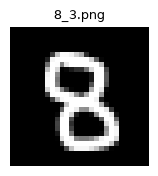

Success: Image 8_3.png is for digit 8 is recognized as 8.


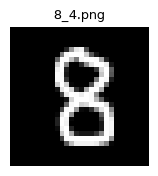

Success: Image 8_4.png is for digit 8 is recognized as 8.


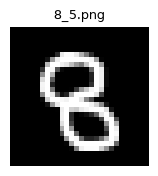

Success: Image 8_5.png is for digit 8 is recognized as 8.


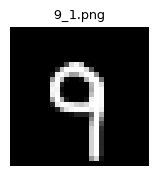

Success: Image 9_1.png is for digit 9 is recognized as 9.


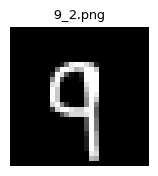

Success: Image 9_2.png is for digit 9 is recognized as 9.


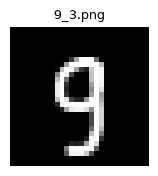

Success: Image 9_3.png is for digit 9 is recognized as 9.


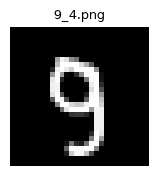

Success: Image 9_4.png is for digit 9 is recognized as 9.


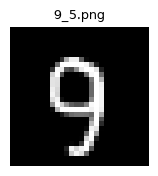

Success: Image 9_5.png is for digit 9 is recognized as 9.


In [6]:
results = []
for digit in range(10):
    for ver in range(1, 6):
        results.append(mnist.test(f"images/{digit}_{ver}.png"))

## 5. Results

In [7]:
expected = np.array([r[0] for r in results])
predicted = np.array([r[1] for r in results])
print(f"Recognized {np.sum(expected == predicted)} of {len(results)} images "
      f"({np.mean(expected == predicted):.0%})\n")

for d in range(10):
    m = expected == d
    wrong = [int(p) for p in predicted[m & (predicted != d)]]
    print(f"digit {d}: {np.sum(predicted[m] == d)}/5" + (f"   misread as {wrong}" if wrong else ""))

Recognized 48 of 50 images (96%)

digit 0: 5/5
digit 1: 3/5   misread as [2, 2]
digit 2: 5/5
digit 3: 5/5
digit 4: 5/5
digit 5: 5/5
digit 6: 5/5
digit 7: 5/5
digit 8: 5/5
digit 9: 5/5


**Discussion.** The network recognized **48 of my 50** handwritten digits (96%), close to the 93.5% it gets on the official MNIST test set.

Both failures were the digit 1: `1_3.png` and `1_4.png` were read as **2**. In those two images I drew the 1 with a flag at the top and a wide flat base. MNIST 1s are almost always a single vertical stroke, so a 1 with a horizontal base looks more like the bottom stroke of a 2 to this network. My other three 1s, with little or no base, were recognized correctly.

This shows the network learned the handwriting style in MNIST rather than an abstract idea of each digit. Inputs that follow the MNIST convention (white digit on black, fitted into 20×20 and centred by mass in 28×28) are recognized well, and unusual stroke styles are where it fails.